# Bird Song Classifier: Custom CNN vs. Transfer Learning

Classification of 22 Central European bird species from [Xeno-canto](https://xeno-canto.org) recordings. Audio is cut into 5-second windows and converted to mel-spectrograms, which are classified by:

- **ResNet18** pretrained on ImageNet (transfer learning),
- **CustomBirdNet**, a residual CNN with the same depth as ResNet18, trained from scratch,
- **CustomBirdNetV2**, a smaller residual CNN with dropout and a lower learning rate.

Data are split into training, validation and test sets **by recording**, so the test set contains only recordings the models have never seen.

*Course project, Machine Learning for Bioinformatics (MSc, Jagiellonian University), 2025/2026.*
*Authors: Weronika Czop and Klaudia Zięba*

## 1. Data download

In [ ]:
# Download recordings from Xeno-canto

import os
from xcapi import XenoCantoClient, Downloader, QueryBuilder

# Xeno-canto API key is read from an environment variable, never stored in the code
# (in the terminal, before starting Jupyter: export XC_API_KEY=your_key)
API_KEY = os.environ["XC_API_KEY"]
client = XenoCantoClient(api_key=API_KEY)
downloader = Downloader(output_dir="./dataset")

# Species list
species_list = [
    "Turdus merula",
    "Turdus philomelos",
    "Parus major",
    "Sylvia atricapilla",
    "Phylloscopus collybita",
    "Columba palumbus",
    "Corvus cornix",
    "Cyanistes caeruleus",
    "Coloeus monedula",
    "Pica pica",
    "Fringilla coelebs",
    "Cuculus canorus",
    "Curruca curruca",
    "Dendrocopos major",
    "Curruca communis",
    "Garrulus glandarius",
    "Carpodacus erythrinus",
    "Oriolus oriolus",
    "Erithacus rubecula",
    "Picus viridis",
    "Sitta europaea",
    "Aegithalos caudatus"
]

# Query the database

for species in species_list:
    query = (
        QueryBuilder()
        .group("birds")
        .species(species)
        .quality("A") # changed to "B" for species with too few quality-A recordings
        .build()
    ) + " box:45.905300,11.931152,54.175297,27.004395" # bounding box: Central/Eastern Europe

    all_recordings = client.search(query)
    total = len(all_recordings)
    selected = all_recordings[:100] # at most 100 recordings per species

    print(f"{species}: {total} available recordings, downloading {len(selected)}")
    downloader.download_recordings(selected)


print("Done")

## 2. From audio to CNN input: a single-recording walkthrough

In [1]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import os

In [2]:
# Load a single recording

file_path = "./dataset/Parus_major/XC153792-Parus_major_Poland_Jarek_Matusiak_20131103_06.mp3"

# sr=22050 Hz: a common sample rate in audio ML, half of CD quality; covers bird song and halves the data size
# (without sr, librosa keeps the original rate, usually 44,100 Hz)
signal, sr = librosa.load(file_path, sr=22050)

print(f"Sample rate: {sr} Hz")
print(f"Signal length: {len(signal)} samples")
print(f"Duration time: {len(signal)/sr:.2f} s")

Sample rate: 22050 Hz
Signal length: 2392128 samples
Duration time: 108.49 s


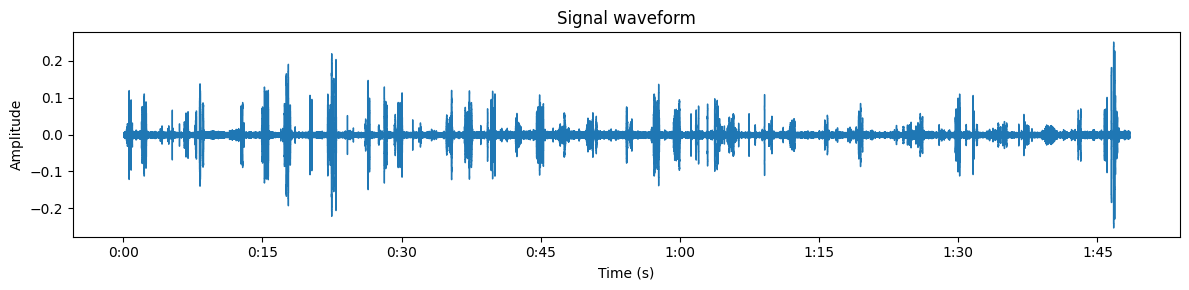

In [3]:
# Raw waveform

plt.figure(figsize=(12, 3))
librosa.display.waveshow(signal, sr=sr)
plt.title("Signal waveform")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()

The song starts almost immediately (no long initial silence) and shows regular bursts of activity, i.e. successive phrases of the great tit's song, separated by short pauses.

In [4]:
# Activity segmentation: split the recording into windows and drop the silent ones

# Window length and hop in seconds
WINDOW_SEC = 5.0
HOP_SEC = 2.5  # 50% overlap between windows → more training samples

# Convert to samples
window_size = int(WINDOW_SEC * sr)   # 5s × 22050 = 110,250 samples
hop_size = int(HOP_SEC * sr)         # 2.5s × 22050 = 55,125 samples

# RMS energy threshold: quieter windows are treated as silence
RMS_THRESHOLD = 0.01

segments = []

for start in range(0, len(signal) - window_size, hop_size):
    end = start + window_size
    window = signal[start:end]
    
    # RMS (root mean square) = sqrt(mean of squared samples), a measure of loudness
    rms = np.sqrt(np.mean(window**2))
    
    if rms > RMS_THRESHOLD:
        segments.append(window)

total_windows = len(segments) + sum(
    1 for start in range(0, len(signal) - window_size, hop_size)
    if np.sqrt(np.mean(signal[start:start+window_size]**2)) <= RMS_THRESHOLD
)

print(f"Total windows: {total_windows}")
print(f"Active signal windows: {len(segments)}")
print(f"Rejected windows (silence): {total_windows - len(segments)}")

Total windows: 42
Active signal windows: 18
Rejected windows (silence): 24


In [5]:
# Mel-spectrogram of a single window

# First active window
segment = segments[0]

# n_mels=128: number of mel frequency bands
# n_fft=2048: FFT window size (frequency resolution)
# hop_length=512: step between FFT windows in samples (time resolution)
mel_spec = librosa.feature.melspectrogram(
    y=segment,
    sr=sr,
    n_mels=128,
    n_fft=2048,
    hop_length=512
)

# Convert to decibels: a log scale matches human hearing and works better for ML models
# ref=np.max scales relative to the loudest value in the spectrogram
mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)

print(f"Spectrogram shape: {mel_spec_db.shape}")
print("(mel bands × time frames)")

Spectrogram shape: (128, 216)
(mel bands × time frames)


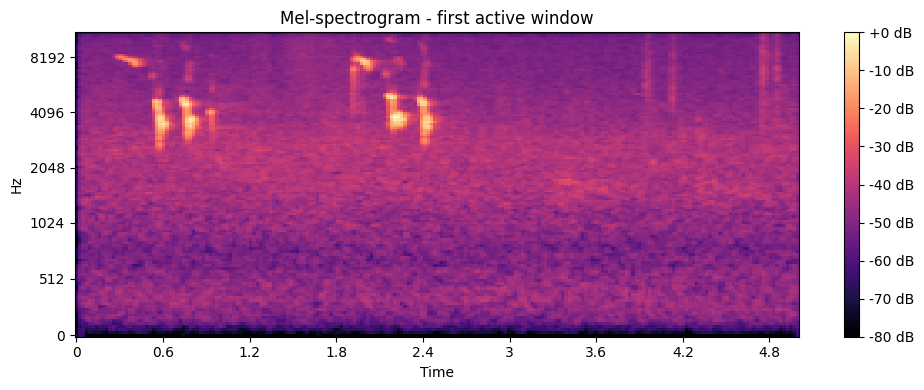

In [6]:
# Plot

plt.figure(figsize=(10, 4))
librosa.display.specshow(
    mel_spec_db,
    sr=sr,
    hop_length=512,
    x_axis="time",
    y_axis="mel"
)
plt.colorbar(format="%+2.0f dB")
plt.title("Mel-spectrogram - first active window")
plt.tight_layout()
plt.show()

- Bright vertical structures in the upper half (4,000–8,000 Hz) are individual notes of the great tit's song, clearly separated from each other.
- The characteristic downward "tails" are typical of frequency-modulated signals: the bird changes pitch within each note.
- The bottom of the spectrogram (0–1,000 Hz) is dark: background noise only, as the great tit produces almost no sound in this range.

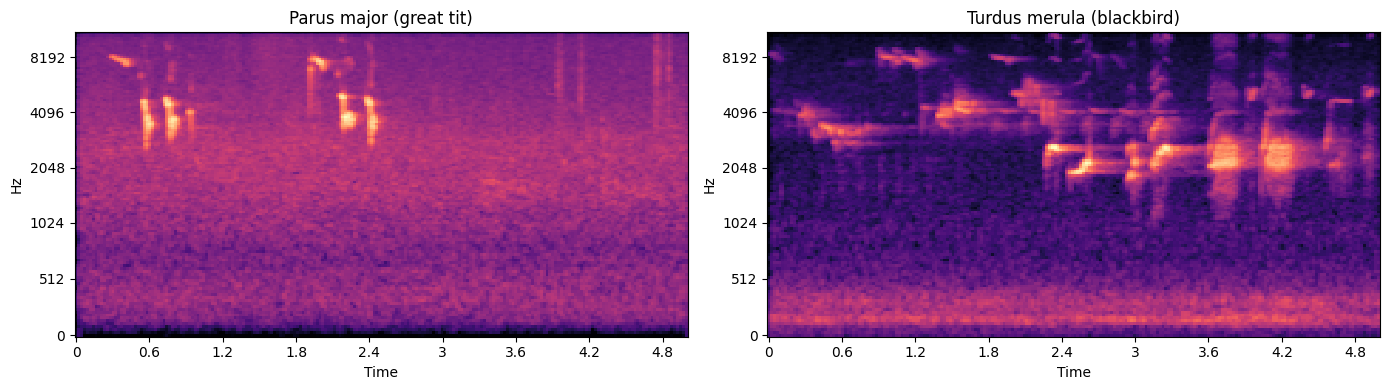

In [7]:
# Comparison: great tit vs. blackbird

# Load a blackbird recording
signal_kos, sr = librosa.load("./dataset/Turdus_merula/XC172669-Amsel Gesang 3.mp3", sr=22050)

# For simplicity, take the first 5 seconds
segment_kos = signal_kos[:window_size]

mel_kos = librosa.power_to_db(
    librosa.feature.melspectrogram(y=segment_kos, sr=sr, n_mels=128, n_fft=2048, hop_length=512),
    ref=np.max
)

# Side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

librosa.display.specshow(mel_spec_db, sr=sr, hop_length=512, x_axis="time", y_axis="mel", ax=axes[0])
axes[0].set_title("Parus major (great tit)")

librosa.display.specshow(mel_kos, sr=sr, hop_length=512, x_axis="time", y_axis="mel", ax=axes[1])
axes[1].set_title("Turdus merula (blackbird)")

plt.tight_layout()
plt.show()

**Why do the background colours differ so much?**

This is an effect of `ref=np.max`: each spectrogram is scaled relative to its own maximum. The blackbird has very loud, energetic notes (bright streaks), so its maximum is high and everything else (background noise, pauses) appears very dark in comparison.

Normalising every spectrogram to [0, 1] in the preprocessing step removes this difference.

## 3. Preprocessing of the full dataset

Each recording is resampled to 22,050 Hz, cut into 5 s windows with 50% overlap, and silent windows (RMS ≤ 0.01) are discarded. Each remaining window becomes a 128 × 216 mel-spectrogram in dB, min-max normalised to [0, 1].

Because neighbouring windows overlap, windows from the same recording are nearly identical. The data are therefore split **by recording** (70/15/15, stratified by species): all windows of a recording end up in the same set. The validation set is used for early stopping; the test set is used only once, for the final evaluation.

In [8]:
# Full preprocessing of a single file

def process_audio_file(file_path, sr=22050, window_sec=5.0, hop_sec=2.5,
                       rms_threshold=0.01, n_mels=128, n_fft=2048, hop_length=512):
    """
    Load an audio file, keep the active 5 s windows
    and return them as a list of normalised mel-spectrograms.
    """
    signal, sr = librosa.load(file_path, sr=sr)
    
    window_size = int(window_sec * sr)
    hop_size = int(hop_sec * sr)
    
    spectrograms = []
    
    for start in range(0, len(signal) - window_size, hop_size):
        window = signal[start:start + window_size]
        
        # Skip silent windows
        rms = np.sqrt(np.mean(window**2))
        if rms <= rms_threshold:
            continue
        
        # Mel-spectrogram → decibels
        mel = librosa.feature.melspectrogram(
            y=window, sr=sr, n_mels=n_mels, n_fft=n_fft, hop_length=hop_length
        )
        mel_db = librosa.power_to_db(mel, ref=np.max)
        
        # Min-max normalisation to [0, 1]: quietest pixel → 0, loudest → 1
        # (mel_db is always ≤ 0 because ref=np.max sets the maximum to 0 dB)
        mel_norm = (mel_db - mel_db.min()) / (mel_db.max() - mel_db.min())
        
        spectrograms.append(mel_norm)
    
    return spectrograms  # list of (128, 216) arrays

In [9]:
from pathlib import Path

DATASET_DIR = "./dataset"
SPECIES = [
    "Turdus_merula",
    "Turdus_philomelos",
    "Parus_major",
    "Sylvia_atricapilla",
    "Phylloscopus_collybita",
    "Columba_palumbus",
    "Corvus_cornix",
    "Cyanistes_caeruleus",
    "Coloeus_monedula",
    "Pica_pica",
    "Fringilla_coelebs",
    "Cuculus_canorus",
    "Curruca_curruca",
    "Dendrocopos_major",
    "Curruca_communis",
    "Garrulus_glandarius",
    "Carpodacus_erythrinus",
    "Oriolus_oriolus",
    "Erithacus_rubecula",
    "Picus_viridis",
    "Sitta_europaea",
    "Aegithalos_caudatus"
]

# Species → class index
label_map = {species: idx for idx, species in enumerate(SPECIES)}
print("Mapping class:", label_map)

all_specs = []   # spectrograms
all_labels = []  # class labels
all_groups = []  # source recording of each spectrogram (used for the split)

for species in SPECIES:
    species_dir = Path(DATASET_DIR) / species
    files = list(species_dir.glob("*.mp3")) + list(species_dir.glob("*.wav")) # both audio formats
    print(f"\n{species}: {len(files)} files")
    
    for file_path in files:
        specs = process_audio_file(str(file_path))
        for spec in specs:
            all_specs.append(spec)
            all_labels.append(label_map[species])
            all_groups.append(file_path.stem)

all_specs = np.array(all_specs)    # shape: (N, 128, 216)
all_labels = np.array(all_labels)  # shape: (N,)
all_groups = np.array(all_groups)  # shape: (N,)

print(f"\nTotal number of spectrograms: {len(all_specs)}")
print(f"Spectrogram shape: {all_specs[0].shape}")

Mapping class: {'Turdus_merula': 0, 'Turdus_philomelos': 1, 'Parus_major': 2, 'Sylvia_atricapilla': 3, 'Phylloscopus_collybita': 4, 'Columba_palumbus': 5, 'Corvus_cornix': 6, 'Cyanistes_caeruleus': 7, 'Coloeus_monedula': 8, 'Pica_pica': 9, 'Fringilla_coelebs': 10, 'Cuculus_canorus': 11, 'Curruca_curruca': 12, 'Dendrocopos_major': 13, 'Curruca_communis': 14, 'Garrulus_glandarius': 15, 'Carpodacus_erythrinus': 16, 'Oriolus_oriolus': 17, 'Erithacus_rubecula': 18, 'Picus_viridis': 19, 'Sitta_europaea': 20, 'Aegithalos_caudatus': 21}

Turdus_merula: 100 files

Turdus_philomelos: 100 files

Parus_major: 100 files

Sylvia_atricapilla: 99 files



Phylloscopus_collybita: 99 files

Columba_palumbus: 96 files



Corvus_cornix: 100 files

Cyanistes_caeruleus: 100 files


Note: Illegal Audio-MPEG-Header 0x4b656c65 at offset 465664.
Note: Trying to resync...
Note: Hit end of (available) data during resync.
Note: Illegal Audio-MPEG-Header 0x69646165 at offset 650752.
Note: Trying to resync...
Note: Hit end of (available) data during resync.



Coloeus_monedula: 77 files


...

Note: Illegal Audio-MPEG-Header 0x696e7573 at offset 64701.
Note: Trying to resync...
Note: Hit end of (available) data during resync.
Note: Illegal Audio-MPEG-Header 0x00000047 at offset 506065.
Note: Trying to resync...
Note: Hit end of (available) data during resync.
Note: Illegal Audio-MPEG-Header 0x7573290c at offset 247349.
Note: Trying to resync...
Note: Hit end of (available) data during resync.
Note: Illegal Audio-MPEG-Header 0x651a0000 at offset 325888.
Note: Trying to resync...
Note: Hit end of (available) data during resync.



Oriolus_oriolus: 100 files

Erithacus_rubecula: 92 files

Picus_viridis: 100 files



Sitta_europaea: 98 files

Aegithalos_caudatus: 99 files


Note: Illegal Audio-MPEG-Header 0x6261636b at offset 2594397.
Note: Trying to resync...
Note: Hit end of (available) data during resync.
Note: Illegal Audio-MPEG-Header 0x636f6c64 at offset 3328960.
Note: Trying to resync...
Note: Hit end of (available) data during resync.



Total number of spectrograms: 39858
Spectrogram shape: (128, 216)


In [10]:
# Train / validation / test split

from sklearn.model_selection import StratifiedGroupKFold

# 70/15/15 split BY RECORDING, not by spectrogram.
# Windows overlap by 50%, so neighbouring spectrograms of one recording are nearly identical.
# If they ended up in both training and test sets, the model would recognise the recording
# rather than the species, and the test score would be inflated. All windows of a recording
# therefore go to the same set (groups=all_groups); stratification keeps species proportions.

# Hold out ~15% of recordings for testing
sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42)
trainval_idx, test_idx = next(sgkf.split(all_specs, all_labels, groups=all_groups))

# From the rest, ~15% of the total for validation (early stopping)
sgkf_val = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
tr, va = next(sgkf_val.split(trainval_idx, all_labels[trainval_idx], groups=all_groups[trainval_idx]))
train_idx, val_idx = trainval_idx[tr], trainval_idx[va]

# Sanity check: no recording may appear in two sets
assert not set(all_groups[train_idx]) & set(all_groups[test_idx])
assert not set(all_groups[train_idx]) & set(all_groups[val_idx])
assert not set(all_groups[val_idx]) & set(all_groups[test_idx])

X_train, y_train = all_specs[train_idx], all_labels[train_idx]
X_val,   y_val   = all_specs[val_idx],   all_labels[val_idx]
X_test,  y_test  = all_specs[test_idx],  all_labels[test_idx]

for name, idx in [("Train", train_idx), ("Val", val_idx), ("Test", test_idx)]:
    print(f"{name:5s} set: {len(idx):6d} spectrograms from {len(np.unique(all_groups[idx])):4d} recordings")

# Class distribution per set
print(f"\n{'Species':25s} {'train':>6s} {'val':>6s} {'test':>6s}")
for species, idx in label_map.items():
    print(f"  {species:23s} {np.sum(y_train == idx):6d} {np.sum(y_val == idx):6d} {np.sum(y_test == idx):6d}")

Train set:  28385 spectrograms from 1275 recordings
Val   set:   5799 spectrograms from  252 recordings
Test  set:   5674 spectrograms from  258 recordings

Species                    train    val   test
  Turdus_merula             2438    488    489
  Turdus_philomelos         3772    753    753
  Parus_major               1331    265    265
  Sylvia_atricapilla        2405    479    480
  Phylloscopus_collybita    1697    339    339
  Columba_palumbus          1035    207    207
  Corvus_cornix              151     30     30
  Cyanistes_caeruleus       1067    213    213
  Coloeus_monedula           370     73     74
  Pica_pica                  602    120    121
  Fringilla_coelebs         1742    348    349
  Cuculus_canorus           1121    224    225
  Curruca_curruca            740    148    148
  Dendrocopos_major         1339    268    268
  Curruca_communis          1428    285    286
  Garrulus_glandarius        595    118    119
  Carpodacus_erythrinus      942    188    1

The number of spectrograms differs strongly between species, because recordings differ in length and in the amount of silence between calls. Instead of discarding data, we use **class weights** in the loss function, so errors on rare classes are penalised more during training.

In [11]:
# Class weights

import torch
from collections import Counter

class_counts = Counter(y_train)
total = len(y_train)

# The rarer the class, the higher its weight
class_weights = {cls: total / count for cls, count in class_counts.items()}
weights_tensor = torch.FloatTensor([class_weights[i] for i in range(len(SPECIES))])

print("Class weights:")
for species, idx in label_map.items():
    print(f"  {species}: {class_weights[idx]:.2f}")

Class weights:
  Turdus_merula: 11.64
  Turdus_philomelos: 7.53
  Parus_major: 21.33
  Sylvia_atricapilla: 11.80
  Phylloscopus_collybita: 16.73
  Columba_palumbus: 27.43
  Corvus_cornix: 187.98
  Cyanistes_caeruleus: 26.60
  Coloeus_monedula: 76.72
  Pica_pica: 47.15
  Fringilla_coelebs: 16.29
  Cuculus_canorus: 25.32
  Curruca_curruca: 38.36
  Dendrocopos_major: 21.20
  Curruca_communis: 19.88
  Garrulus_glandarius: 47.71
  Carpodacus_erythrinus: 30.13
  Oriolus_oriolus: 18.74
  Erithacus_rubecula: 12.84
  Picus_viridis: 95.25
  Sitta_europaea: 28.64
  Aegithalos_caudatus: 47.71


In [12]:
# PyTorch Dataset and DataLoaders

from torch.utils.data import Dataset, DataLoader

class BirdDataset(Dataset):
    def __init__(self, spectrograms, labels):
        # PyTorch CNNs expect (channels, height, width); add a channel dimension:
        # (N, 128, 216) → (N, 1, 128, 216)
        self.X = torch.FloatTensor(spectrograms).unsqueeze(1)
        self.y = torch.LongTensor(labels)
    
    def __len__(self):
        return len(self.y)
    
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# Datasets
train_dataset = BirdDataset(X_train, y_train)
val_dataset   = BirdDataset(X_val, y_val)
test_dataset  = BirdDataset(X_test, y_test)

# DataLoaders feed the data to the model in batches
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True) 
val_loader   = DataLoader(val_dataset,   batch_size=32, shuffle=False) # early stopping
test_loader  = DataLoader(test_dataset,  batch_size=32, shuffle=False) # final evaluation only

print("Batch shape:")
X_batch, y_batch = next(iter(train_loader))
print(f"  X: {X_batch.shape}  →  (batch, channels, mel_bins, time_frames)")
print(f"  y: {y_batch.shape}  →  (batch,)")

Batch shape:
  X: torch.Size([32, 1, 128, 216])  →  (batch, channels, mel_bins, time_frames)
  y: torch.Size([32])  →  (batch,)


## 4. ResNet18: transfer learning

In [13]:
import torchvision.models as models
import torch.nn as nn

# ResNet18 with ImageNet weights
model = models.resnet18(weights="IMAGENET1K_V1")

# First layer: 3 channels → 1; averaging the RGB filters keeps the pretrained features
old_weight = model.conv1.weight.data  # shape: (64, 3, 7, 7)
new_weight = old_weight.mean(dim=1, keepdim=True)  # shape: (64, 1, 7, 7)

model.conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
model.conv1.weight.data = new_weight

# Last layer: 1000 → 22 classes
num_features = model.fc.in_features  # 512
model.fc = nn.Linear(num_features, len(SPECIES))

print(model.fc)
print(f"\nNumber of parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

Linear(in_features=512, out_features=22, bias=True)

Number of parameters: 11,181,526
Trainable parameters: 11,181,526


**ResNet18** is a convolutional neural network pretrained on ImageNet, a dataset of 1.2 million photos in 1,000 categories. During that training it learned to detect generic visual patterns (edges, textures, shapes), which are also useful for spectrograms.

Modifications:

- **Input: 3 channels → 1.** ResNet was trained on RGB images, while a spectrogram has a single channel (energy in a given frequency band at a given time). Instead of initialising the new layer randomly, we average the pretrained RGB filters, which preserves the ImageNet features.
- **Output: 1,000 classes → 22.** The original classifier is replaced with a new linear layer with one output per species. This is the only randomly initialised layer.

All ~11.2M parameters are fine-tuned. The pretrained layers change relatively little, while the new output layer learns the species from scratch.

### Training: ResNet18

The pretrained network is fine-tuned with a lower learning rate (0.0001) than the networks trained from scratch (0.001), so the ImageNet features are adjusted gradually rather than overwritten.

In [14]:
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using: {device}")

model = model.to(device)
weights_tensor = weights_tensor.to(device)

# Class-weighted loss
criterion = nn.CrossEntropyLoss(weight=weights_tensor)

# Adam optimiser; lr = 0.0001, i.e. small steps so fine-tuning does not overwrite the pretrained features
optimizer = optim.Adam(model.parameters(), lr=0.0001)

# Epochs and early stopping
EPOCHS = 30
PATIENCE = 5  # same for all models
best_val_loss = float("inf")
epochs_no_improve = 0
best_model_weights = None

# For learning curves
history_resnet = {
    'train_loss': [], 'val_loss': [],
    'train_acc':  [], 'val_acc':  []
}

for epoch in range(EPOCHS):
    # TRAINING
    model.train()
    train_loss = 0.0
    correct = 0
    total = 0

    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        optimizer.zero_grad()       # reset gradients from the previous batch
        outputs = model(X_batch)    # forward pass
        loss = criterion(outputs, y_batch)  # compute loss
        loss.backward()             # backward pass: compute gradients
        optimizer.step()            # update weights

        train_loss += loss.item()
        predicted = outputs.argmax(dim=1)
        correct += (predicted == y_batch).sum().item()
        total += len(y_batch)

    train_acc = correct / total

    # EVALUATION ON THE VALIDATION SET (the test set is kept for the end)
    model.eval()
    val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad(): # no gradients needed for evaluation
        for X_batch, y_batch in val_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)

            val_loss += loss.item()
            predicted = outputs.argmax(dim=1)
            correct += (predicted == y_batch).sum().item()
            total += len(y_batch)

    val_acc = correct / total

    history_resnet['train_loss'].append(train_loss / len(train_loader))
    history_resnet['val_loss'].append(val_loss / len(val_loader))
    history_resnet['train_acc'].append(train_acc)
    history_resnet['val_acc'].append(val_acc)

    print(f"Epoch {epoch+1:2d}/{EPOCHS} | "
          f"Train loss: {train_loss/len(train_loader):.4f} | "
          f"Train acc: {train_acc:.4f} | "
          f"Val loss: {val_loss/len(val_loader):.4f} | "
          f"Val acc: {val_acc:.4f}")

    # Early stopping
    if val_loss / len(val_loader) < best_val_loss:
        best_val_loss = val_loss / len(val_loader)
        epochs_no_improve = 0
        best_epoch = epoch + 1
        # clone() copies the tensors; state_dict().copy() would only copy references, so the "best" weights would keep changing
        best_model_weights = {k: v.clone() for k, v in model.state_dict().items()}
    else:
        epochs_no_improve += 1
        print(f"  → No improvement for {epochs_no_improve} epoch(s) (patience: {PATIENCE})")
        if epochs_no_improve >= PATIENCE:
            print(f"\nEarly stopping triggered after epoch {epoch+1}!")
            break

model.load_state_dict(best_model_weights)
print(f"Best model weights restored (epoch {best_epoch}).")

Using: cuda
Epoch  1/30 | Train loss: 0.5498 | Train acc: 0.8522 | Val loss: 0.8026 | Val acc: 0.7979
Epoch  2/30 | Train loss: 0.1085 | Train acc: 0.9694 | Val loss: 0.9673 | Val acc: 0.7732
  → No improvement for 1 epoch(s) (patience: 5)
Epoch  3/30 | Train loss: 0.0583 | Train acc: 0.9842 | Val loss: 1.2717 | Val acc: 0.7403
  → No improvement for 2 epoch(s) (patience: 5)
Epoch  4/30 | Train loss: 0.0335 | Train acc: 0.9904 | Val loss: 1.0165 | Val acc: 0.7831
  → No improvement for 3 epoch(s) (patience: 5)
Epoch  5/30 | Train loss: 0.0511 | Train acc: 0.9879 | Val loss: 1.0700 | Val acc: 0.7857
  → No improvement for 4 epoch(s) (patience: 5)
Epoch  6/30 | Train loss: 0.0376 | Train acc: 0.9893 | Val loss: 1.0255 | Val acc: 0.7867
  → No improvement for 5 epoch(s) (patience: 5)

Early stopping triggered after epoch 6!
Best model weights restored (epoch 1).


After training, the weights from the epoch with the lowest validation loss are restored (epoch number printed above).

With the pretrained weights, ResNet18 reaches its lowest validation loss already after the first epoch. From then on, training accuracy approaches 99% while validation loss increases, so the model quickly starts to fit the training recordings rather than the species.

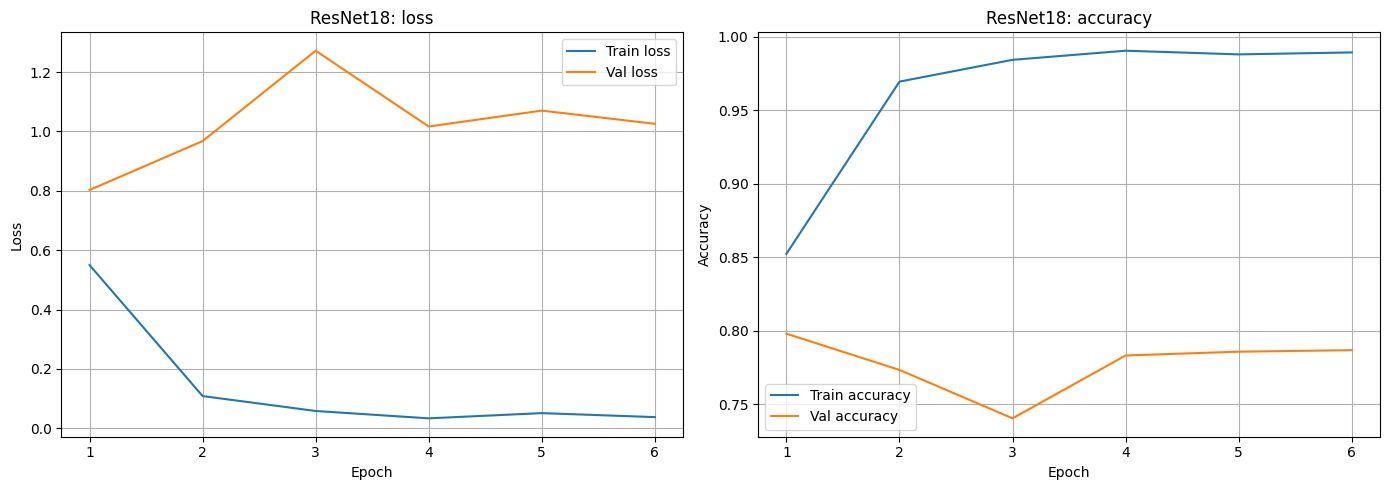

In [15]:
# Learning curves: ResNet18

x_axis_resnet = range(1, len(history_resnet['train_loss']) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(x_axis_resnet, history_resnet['train_loss'], label='Train loss')
ax1.plot(x_axis_resnet, history_resnet['val_loss'],   label='Val loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('ResNet18: loss')
ax1.legend()
ax1.grid(True)

ax2.plot(x_axis_resnet, history_resnet['train_acc'], label='Train accuracy')
ax2.plot(x_axis_resnet, history_resnet['val_acc'],   label='Val accuracy')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.set_title('ResNet18: accuracy')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

### Evaluation on the test set

Each model is evaluated twice:
- **window level**: every 5 s spectrogram is classified independently,
- **recording level**: the predicted probabilities of all windows of a recording are averaged, giving one prediction per recording. This is how the classifier would be used on a new field recording.

In [16]:
from sklearn.metrics import confusion_matrix, classification_report, f1_score
import seaborn as sns

test_groups = all_groups[test_idx]  # source recording of each test spectrogram (same order as test_loader)
results = {}                        # test metrics of all models, compared at the end

def evaluate(model, name):
    """Predict on the test set, store window- and recording-level metrics, return window predictions."""
    model.eval()
    probs = []
    with torch.no_grad():
        for X_batch, _ in test_loader:
            probs.append(torch.softmax(model(X_batch.to(device)), dim=1).cpu().numpy())
    probs = np.concatenate(probs)
    y_pred = probs.argmax(axis=1)

    # Recording level: average the window probabilities within each recording
    recordings = np.unique(test_groups)
    rec_true = np.array([y_test[test_groups == r][0] for r in recordings])
    rec_pred = np.array([probs[test_groups == r].mean(axis=0).argmax() for r in recordings])

    results[name] = {
        "window_acc":    (y_pred == y_test).mean(),
        "window_f1":     f1_score(y_test, y_pred, average="macro"),
        "recording_acc": (rec_pred == rec_true).mean(),
        "recording_f1":  f1_score(rec_true, rec_pred, average="macro"),
    }
    r = results[name]
    print(f"{name}")
    print(f"  window level    ({len(y_test)} spectrograms): accuracy {r['window_acc']:.3f}, macro F1 {r['window_f1']:.3f}")
    print(f"  recording level ({len(recordings)} recordings):   accuracy {r['recording_acc']:.3f}, macro F1 {r['recording_f1']:.3f}\n")
    return y_pred

ResNet18
  window level    (5674 spectrograms): accuracy 0.821, macro F1 0.789
  recording level (258 recordings):   accuracy 0.857, macro F1 0.853



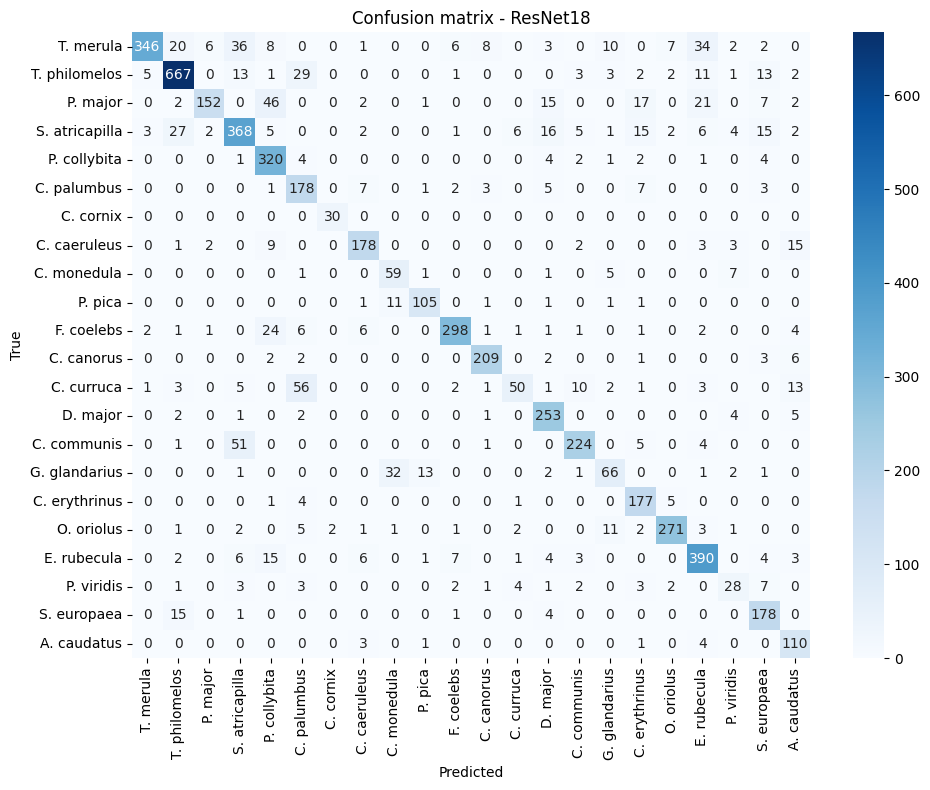

                precision    recall  f1-score   support

     T. merula       0.97      0.71      0.82       489
 T. philomelos       0.90      0.89      0.89       753
      P. major       0.93      0.57      0.71       265
S. atricapilla       0.75      0.77      0.76       480
  P. collybita       0.74      0.94      0.83       339
   C. palumbus       0.61      0.86      0.72       207
     C. cornix       0.94      1.00      0.97        30
  C. caeruleus       0.86      0.84      0.85       213
   C. monedula       0.57      0.80      0.67        74
       P. pica       0.85      0.87      0.86       121
    F. coelebs       0.93      0.85      0.89       349
    C. canorus       0.92      0.93      0.93       225
    C. curruca       0.77      0.34      0.47       148
      D. major       0.81      0.94      0.87       268
   C. communis       0.89      0.78      0.83       286
 G. glandarius       0.66      0.55      0.60       119
 C. erythrinus       0.75      0.94      0.84  

In [17]:
all_preds = evaluate(model, "ResNet18")
all_true  = y_test

# Short names for plots
species_short = [
    "T. merula",
    "T. philomelos",
    "P. major",
    "S. atricapilla",
    "P. collybita",
    "C. palumbus",
    "C. cornix",
    "C. caeruleus",
    "C. monedula",
    "P. pica",
    "F. coelebs",
    "C. canorus",
    "C. curruca",
    "D. major",
    "C. communis",
    "G. glandarius",
    "C. erythrinus",
    "O. oriolus",
    "E. rubecula",
    "P. viridis",
    "S. europaea",
    "A. caudatus"
]

# Confusion matrix
cm = confusion_matrix(all_true, all_preds)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=species_short,
            yticklabels=species_short)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion matrix - ResNet18")
plt.tight_layout()
plt.show()

# Precision, recall and F1 per species
print(classification_report(all_true, all_preds, target_names=species_short))

## 5. Custom CNN trained from scratch

### Architecture: CustomBirdNet

**Key element: the residual block.** Instead of learning a mapping `F(x)` directly, each block learns a residual that is added to its input:
```
output = F(x) + x
```
This lets gradients flow directly through the shortcut, so they do not vanish in deep networks, and makes it easy for a block to learn the identity (`F(x) = 0`).

**Structure (modelled on ResNet18)**, for a 1 × 128 × 216 input:

| Layer | Output (C × H × W) | Notes |
|---|---|---|
| conv1 7×7 + BN + ReLU + MaxPool | 64 × 32 × 54 | stem |
| layer1 (2 × ResBlock, 64 filters) | 64 × 32 × 54 | |
| layer2 (2 × ResBlock, 128 filters) | 128 × 16 × 27 | stride 2 |
| layer3 (2 × ResBlock, 256 filters) | 256 × 8 × 14 | stride 2 |
| layer4 (2 × ResBlock, 512 filters) | 512 × 4 × 7 | stride 2 |
| AdaptiveAvgPool → Flatten | 512 | |
| FC | 22 | classifier |

Total: ~11.2M parameters, the same as ResNet18 but trained from scratch.

In [18]:
import torch.nn.functional as F

### Residual block

In [19]:
class ResidualBlock(nn.Module):
    
    def __init__(self, in_channels, out_channels, stride=1):
        super(ResidualBlock, self).__init__()

        # Main path
        self.conv1 = nn.Conv2d(
            in_channels, out_channels,
            kernel_size=3, stride=stride, padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_channels)

        self.conv2 = nn.Conv2d(
            out_channels, out_channels,
            kernel_size=3, stride=1, padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels)

        # Shortcut
        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels,
                          kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        # Main path
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))

        # Add the shortcut
        out = out + self.shortcut(x)
        out = F.relu(out)
        return out

### Full CustomBirdNet architecture

In [20]:
class CustomBirdNet(nn.Module):

    """    
    Input:  (batch, 1, 128, 216)  - 1 channel, 128 mel bands, 216 time frames
    Output: (batch, num_classes)  - logits for each species
    """

    def __init__(self, num_classes=5):
        super(CustomBirdNet, self).__init__()

        # Stem: 1 channel → 64 feature maps; a large 7×7 kernel captures broad patterns
        self.conv1   = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
        self.bn1     = nn.BatchNorm2d(64)
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)

        # 4 stages of residual blocks
        self.layer1 = self._make_layer(64,  64,  num_blocks=2, stride=1)
        self.layer2 = self._make_layer(64,  128, num_blocks=2, stride=2)
        self.layer3 = self._make_layer(128, 256, num_blocks=2, stride=2)
        self.layer4 = self._make_layer(256, 512, num_blocks=2, stride=2)

        # Global pooling + classifier
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc      = nn.Linear(512, num_classes)

        # Weight initialisation (Kaiming for conv, constants for BN)
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

    def _make_layer(self, in_channels, out_channels, num_blocks, stride):

        layers = [ResidualBlock(in_channels, out_channels, stride)]
        for _ in range(1, num_blocks):
            layers.append(ResidualBlock(out_channels, out_channels, stride=1))
        return nn.Sequential(*layers)

    def forward(self, x):
        # Stem
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.maxpool(x)

        # 4 stages of residual blocks
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)

        # Classification
        x = self.avgpool(x)
        x = x.view(x.size(0), -1)  # flatten: (batch, 512, 1, 1) → (batch, 512)
        x = self.fc(x)
        return x

### Model initialisation and summary

In [21]:
model = CustomBirdNet(num_classes=len(SPECIES))

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print('=' * 55)
print('           CustomBirdNet - summary')
print('=' * 55)
print(model)
print('=' * 55)
print(f'All parameters:       {total_params:>12,}')
print(f'Trainable parameters: {trainable_params:>12,}')
print('=' * 55)
print('\nFor comparison: ResNet18 with a 22-class head has 11,181,526 parameters')

           CustomBirdNet - summary
CustomBirdNet(
  (conv1): Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): ResidualBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (shortcut): Sequential()
    )
    (1): ResidualBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Con

In [22]:
# Forward pass on a dummy batch

model.eval()
with torch.no_grad():
    dummy_input  = torch.zeros(4, 1, 128, 216)  # batch=4, 1 channel, 128 mel bands, 216 frames
    dummy_output = model(dummy_input)

print(f'Input:  {dummy_input.shape}')
print(f'Output:  {dummy_output.shape} - (batch, n_classes)')

Input:  torch.Size([4, 1, 128, 216])
Output:  torch.Size([4, 22]) - (batch, n_classes)


### Training: CustomBirdNet

Same settings as for ResNet18, except for the learning rate (the network starts from random weights):
- **Adam** optimiser (lr = 0.001)
- **CrossEntropyLoss** with class weights
- **early stopping** on the validation set (patience = 5)
- at most **30 epochs**

In [23]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using: {device}')

model = model.to(device)
weights_tensor = weights_tensor.to(device)

criterion = nn.CrossEntropyLoss(weight=weights_tensor)
optimizer = optim.Adam(model.parameters(), lr=0.001)

EPOCHS   = 30
PATIENCE = 5
best_val_loss    = float('inf')
epochs_no_improve = 0
best_model_weights = None

# For learning curves
history = {
    'train_loss': [], 'val_loss': [],
    'train_acc':  [], 'val_acc':  []
}

for epoch in range(EPOCHS):

    # TRAINING
    model.train()
    train_loss = 0.0
    correct = total = 0

    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        optimizer.zero_grad()
        outputs = model(X_batch)
        loss    = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        predicted   = outputs.argmax(dim=1)
        correct    += (predicted == y_batch).sum().item()
        total      += len(y_batch)

    train_acc = correct / total

    # EVALUATION ON THE VALIDATION SET
    model.eval()
    val_loss = 0.0
    correct = total = 0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            outputs  = model(X_batch)
            loss     = criterion(outputs, y_batch)
            val_loss += loss.item()
            predicted  = outputs.argmax(dim=1)
            correct   += (predicted == y_batch).sum().item()
            total     += len(y_batch)

    val_acc = correct / total
    avg_train_loss = train_loss / len(train_loader)
    avg_val_loss  = val_loss  / len(val_loader)

    history['train_loss'].append(avg_train_loss)
    history['val_loss'].append(avg_val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)

    print(f'Epoch {epoch+1:2d}/{EPOCHS} | '
          f'Train loss: {avg_train_loss:.4f} | '
          f'Train acc: {train_acc:.4f} | '
          f'Val loss: {avg_val_loss:.4f} | '
          f'Val acc: {val_acc:.4f}')

    # Early stopping
    if avg_val_loss < best_val_loss:
        best_val_loss     = avg_val_loss
        epochs_no_improve  = 0
        best_epoch = epoch + 1
        best_model_weights = {k: v.clone() for k, v in model.state_dict().items()}
    else:
        epochs_no_improve += 1
        print(f"  → No improvement for {epochs_no_improve} epoch(s) (patience: {PATIENCE})")
        if epochs_no_improve >= PATIENCE:
            print(f"\nEarly stopping triggered after epoch {epoch+1}!")
            break

model.load_state_dict(best_model_weights)
print(f'\nBest model weights restored (epoch {best_epoch}).')

Using: cuda
Epoch  1/30 | Train loss: 1.1241 | Train acc: 0.6595 | Val loss: 1.5229 | Val acc: 0.5861
Epoch  2/30 | Train loss: 0.4680 | Train acc: 0.8570 | Val loss: 1.1069 | Val acc: 0.7103
Epoch  3/30 | Train loss: 0.2687 | Train acc: 0.9128 | Val loss: 1.3158 | Val acc: 0.7237
  → No improvement for 1 epoch(s) (patience: 5)
Epoch  4/30 | Train loss: 0.1769 | Train acc: 0.9402 | Val loss: 1.6582 | Val acc: 0.6430
  → No improvement for 2 epoch(s) (patience: 5)
Epoch  5/30 | Train loss: 0.1259 | Train acc: 0.9564 | Val loss: 1.6428 | Val acc: 0.6855
  → No improvement for 3 epoch(s) (patience: 5)
Epoch  6/30 | Train loss: 0.1194 | Train acc: 0.9581 | Val loss: 1.2755 | Val acc: 0.7441
  → No improvement for 4 epoch(s) (patience: 5)
Epoch  7/30 | Train loss: 0.0834 | Train acc: 0.9713 | Val loss: 1.3393 | Val acc: 0.7598
  → No improvement for 5 epoch(s) (patience: 5)

Early stopping triggered after epoch 7!

Best model weights restored (epoch 2).


After training, the weights from the epoch with the lowest validation loss are restored (epoch number printed above).

### Wyniki i wizualizacja

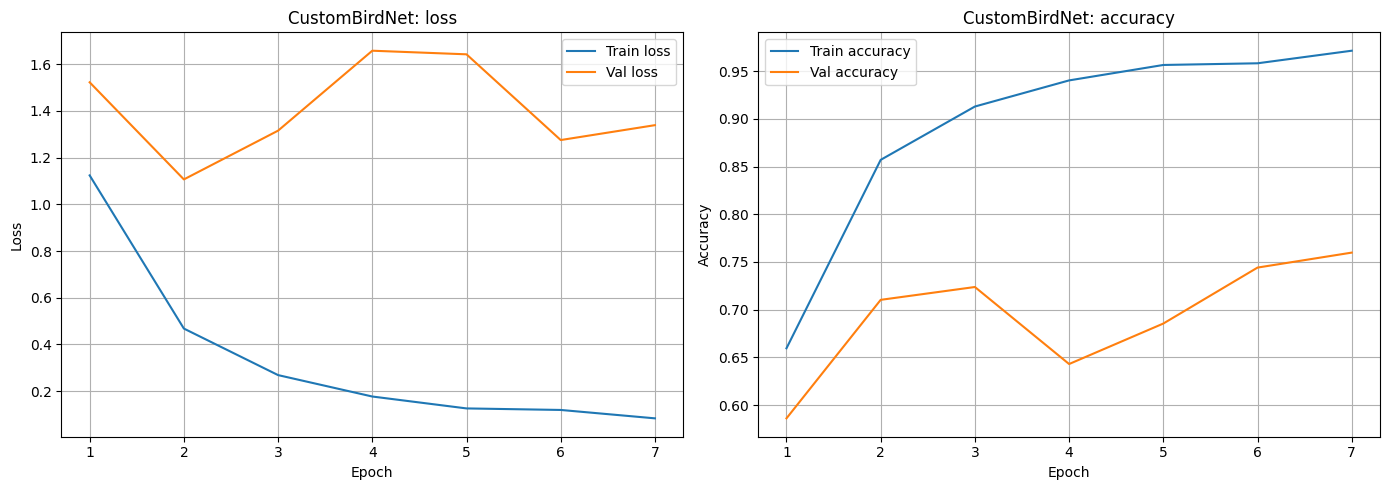

In [24]:
# Learning curves

epochs_ran = len(history['train_loss'])
x_axis     = range(1, epochs_ran + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(x_axis, history['train_loss'], label='Train loss')
ax1.plot(x_axis, history['val_loss'],   label='Val loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('CustomBirdNet: loss')
ax1.legend()
ax1.grid(True)

ax2.plot(x_axis, history['train_acc'], label='Train accuracy')
ax2.plot(x_axis, history['val_acc'],   label='Val accuracy')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.set_title('CustomBirdNet: accuracy')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

CustomBirdNet
  window level    (5674 spectrograms): accuracy 0.732, macro F1 0.707
  recording level (258 recordings):   accuracy 0.802, macro F1 0.805



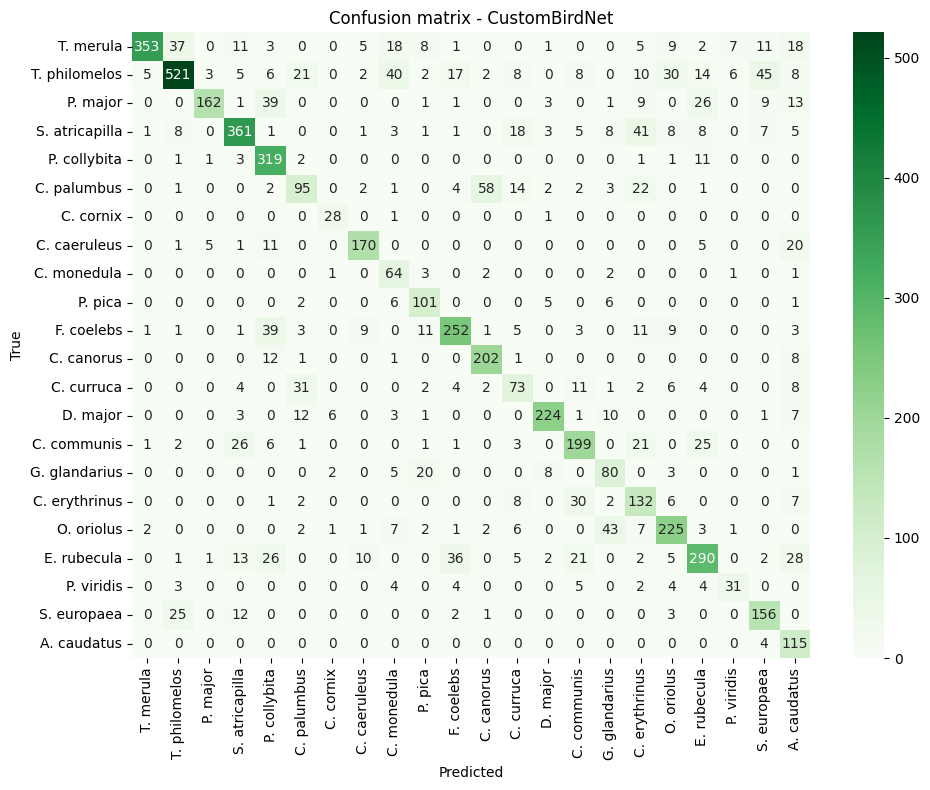

                precision    recall  f1-score   support

     T. merula       0.97      0.72      0.83       489
 T. philomelos       0.87      0.69      0.77       753
      P. major       0.94      0.61      0.74       265
S. atricapilla       0.82      0.75      0.78       480
  P. collybita       0.69      0.94      0.79       339
   C. palumbus       0.55      0.46      0.50       207
     C. cornix       0.74      0.93      0.82        30
  C. caeruleus       0.85      0.80      0.82       213
   C. monedula       0.42      0.86      0.56        74
       P. pica       0.66      0.83      0.74       121
    F. coelebs       0.78      0.72      0.75       349
    C. canorus       0.75      0.90      0.82       225
    C. curruca       0.52      0.49      0.51       148
      D. major       0.90      0.84      0.87       268
   C. communis       0.70      0.70      0.70       286
 G. glandarius       0.51      0.67      0.58       119
 C. erythrinus       0.50      0.70      0.58  

In [25]:
# Evaluation on the test set: confusion matrix and classification report

all_preds = evaluate(model, "CustomBirdNet")
all_true  = y_test

species_short = [
    "T. merula",
    "T. philomelos",
    "P. major",
    "S. atricapilla",
    "P. collybita",
    "C. palumbus",
    "C. cornix",
    "C. caeruleus",
    "C. monedula",
    "P. pica",
    "F. coelebs",
    "C. canorus",
    "C. curruca",
    "D. major",
    "C. communis",
    "G. glandarius",
    "C. erythrinus",
    "O. oriolus",
    "E. rubecula",
    "P. viridis",
    "S. europaea",
    "A. caudatus"
]

cm = confusion_matrix(all_true, all_preds)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=species_short,
            yticklabels=species_short)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion matrix - CustomBirdNet')
plt.tight_layout()
plt.show()

print(classification_report(all_true, all_preds, target_names=species_short))

CustomBirdNet reaches its lowest validation loss at epoch 2. Afterwards training accuracy keeps rising towards 97%, while validation loss increases and validation accuracy fluctuates between 64% and 76%. With ~11M parameters, no pretraining and no regularisation, the network memorises the training recordings instead of learning features that generalise to new ones. On the test set it reaches 0.73 window-level accuracy (macro F1 0.71), clearly below ResNet18.

## 6. CustomBirdNetV2: dropout and a lower learning rate

Changes compared with CustomBirdNet:
- **layer4 removed**: 3 stages instead of 4, ~2.8M parameters instead of ~11M, i.e. less capacity to memorise the training data,
- **Dropout(0.5)** before the final layer,
- **lower learning rate** (0.0003 instead of 0.001) for smoother updates.

In [26]:
class SmallResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super(SmallResidualBlock, self).__init__()

        self.conv1 = nn.Conv2d(in_channels, out_channels,
                               kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels,
                               kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)

        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels,
                          kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + self.shortcut(x)
        out = F.relu(out)
        return out


class CustomBirdNetV2(nn.Module):
    def __init__(self, num_classes=5):
        super(CustomBirdNetV2, self).__init__()

        self.conv1   = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
        self.bn1     = nn.BatchNorm2d(64)
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)

        self.layer1 = self._make_layer(64,  64,  num_blocks=2, stride=1)
        self.layer2 = self._make_layer(64,  128, num_blocks=2, stride=2)
        self.layer3 = self._make_layer(128, 256, num_blocks=2, stride=2)

        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(0.5)
        self.fc      = nn.Linear(256, num_classes)

        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

    def _make_layer(self, in_channels, out_channels, num_blocks, stride):
        layers = [SmallResidualBlock(in_channels, out_channels, stride)]
        for _ in range(1, num_blocks):
            layers.append(SmallResidualBlock(out_channels, out_channels, stride=1))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.maxpool(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.avgpool(x)
        x = x.view(x.size(0), -1)
        x = self.dropout(x)
        x = self.fc(x)
        return x


# Initialisation
model_v2 = CustomBirdNetV2(num_classes=len(SPECIES)).to(device)

total_params_v2 = sum(p.numel() for p in model_v2.parameters())
print(f'CustomBirdNetV2 parameters: {total_params_v2:,}')

criterion_v2 = nn.CrossEntropyLoss(weight=weights_tensor)
optimizer_v2 = optim.Adam(model_v2.parameters(), lr=0.0003)

CustomBirdNetV2 parameters: 2,782,166


In [27]:
EPOCHS_V2   = 30
PATIENCE_V2 = 5
best_val_loss_v2    = float('inf')
epochs_no_improve_v2 = 0
best_model_weights_v2 = None

history_v2 = {
    'train_loss': [], 'val_loss': [],
    'train_acc':  [], 'val_acc':  []
}

for epoch in range(EPOCHS_V2):

    # TRAINING
    model_v2.train()
    train_loss_v2 = 0.0
    correct_v2 = total_v2 = 0

    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        optimizer_v2.zero_grad()
        outputs_v2 = model_v2(X_batch)
        loss_v2    = criterion_v2(outputs_v2, y_batch)
        loss_v2.backward()
        optimizer_v2.step()

        train_loss_v2 += loss_v2.item()
        predicted_v2   = outputs_v2.argmax(dim=1)
        correct_v2    += (predicted_v2 == y_batch).sum().item()
        total_v2      += len(y_batch)

    train_acc_v2 = correct_v2 / total_v2

    # EVALUATION ON THE VALIDATION SET
    model_v2.eval()
    val_loss_v2 = 0.0
    correct_v2 = total_v2 = 0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            outputs_v2  = model_v2(X_batch)
            loss_v2     = criterion_v2(outputs_v2, y_batch)
            val_loss_v2 += loss_v2.item()
            predicted_v2  = outputs_v2.argmax(dim=1)
            correct_v2   += (predicted_v2 == y_batch).sum().item()
            total_v2     += len(y_batch)

    avg_train_loss_v2 = train_loss_v2 / len(train_loader)
    avg_val_loss_v2  = val_loss_v2  / len(val_loader)
    val_acc_v2       = correct_v2 / total_v2

    history_v2['train_loss'].append(avg_train_loss_v2)
    history_v2['val_loss'].append(avg_val_loss_v2)
    history_v2['train_acc'].append(train_acc_v2)
    history_v2['val_acc'].append(val_acc_v2)

    print(f'Epoch {epoch+1:2d}/{EPOCHS_V2} | '
          f'Train loss: {avg_train_loss_v2:.4f} | '
          f'Train acc: {train_acc_v2:.4f} | '
          f'Val loss: {avg_val_loss_v2:.4f} | '
          f'Val acc: {val_acc_v2:.4f}')

    # Early stopping
    if avg_val_loss_v2 < best_val_loss_v2:
        best_val_loss_v2     = avg_val_loss_v2
        epochs_no_improve_v2  = 0
        best_epoch_v2 = epoch + 1
        best_model_weights_v2 = {k: v.clone() for k, v in model_v2.state_dict().items()}
    else:
        epochs_no_improve_v2 += 1
        print(f"  → No improvement for {epochs_no_improve_v2} epoch(s) (patience: {PATIENCE_V2})")
        if epochs_no_improve_v2 >= PATIENCE_V2:
            print(f"\nEarly stopping triggered after epoch {epoch+1}!")
            break

model_v2.load_state_dict(best_model_weights_v2)
print(f'\nBest model weights restored (epoch {best_epoch_v2}).')


Epoch  1/30 | Train loss: 1.4415 | Train acc: 0.5844 | Val loss: 1.8811 | Val acc: 0.4813
Epoch  2/30 | Train loss: 0.5813 | Train acc: 0.8344 | Val loss: 1.7261 | Val acc: 0.5356
Epoch  3/30 | Train loss: 0.3542 | Train acc: 0.8962 | Val loss: 1.2829 | Val acc: 0.6780
Epoch  4/30 | Train loss: 0.2607 | Train acc: 0.9222 | Val loss: 1.6364 | Val acc: 0.5653
  → No improvement for 1 epoch(s) (patience: 5)
Epoch  5/30 | Train loss: 0.2013 | Train acc: 0.9374 | Val loss: 1.1300 | Val acc: 0.7218
Epoch  6/30 | Train loss: 0.1670 | Train acc: 0.9491 | Val loss: 1.8619 | Val acc: 0.6292
  → No improvement for 1 epoch(s) (patience: 5)
Epoch  7/30 | Train loss: 0.1099 | Train acc: 0.9646 | Val loss: 3.6505 | Val acc: 0.3897
  → No improvement for 2 epoch(s) (patience: 5)
Epoch  8/30 | Train loss: 0.1192 | Train acc: 0.9615 | Val loss: 1.2985 | Val acc: 0.7039
  → No improvement for 3 epoch(s) (patience: 5)
Epoch  9/30 | Train loss: 0.0847 | Train acc: 0.9730 | Val loss: 1.2759 | Val acc: 0.744

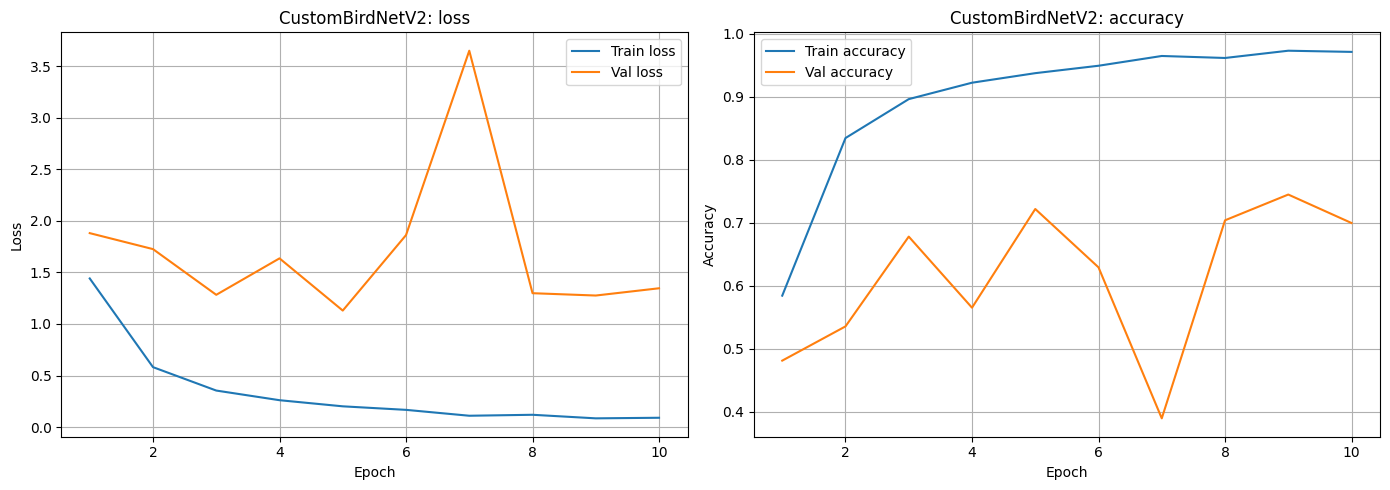

CustomBirdNetV2
  window level    (5674 spectrograms): accuracy 0.759, macro F1 0.722
  recording level (258 recordings):   accuracy 0.802, macro F1 0.800



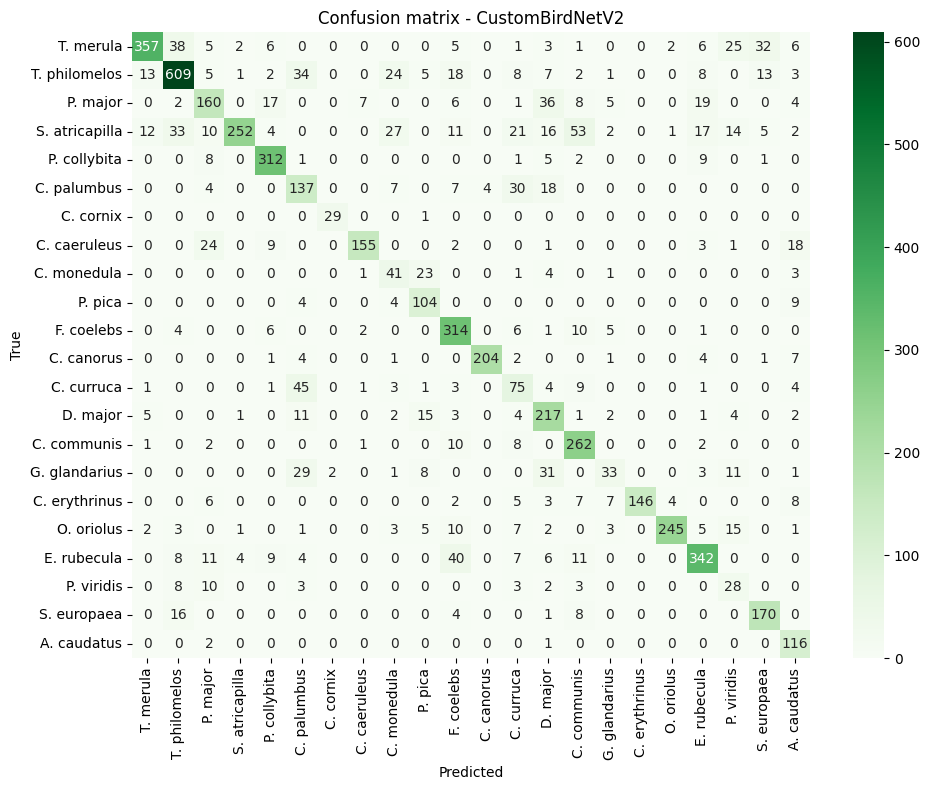

                precision    recall  f1-score   support

     T. merula       0.91      0.73      0.81       489
 T. philomelos       0.84      0.81      0.83       753
      P. major       0.65      0.60      0.62       265
S. atricapilla       0.97      0.53      0.68       480
  P. collybita       0.85      0.92      0.88       339
   C. palumbus       0.50      0.66      0.57       207
     C. cornix       0.94      0.97      0.95        30
  C. caeruleus       0.93      0.73      0.82       213
   C. monedula       0.36      0.55      0.44        74
       P. pica       0.64      0.86      0.73       121
    F. coelebs       0.72      0.90      0.80       349
    C. canorus       0.98      0.91      0.94       225
    C. curruca       0.42      0.51      0.46       148
      D. major       0.61      0.81      0.69       268
   C. communis       0.69      0.92      0.79       286
 G. glandarius       0.55      0.28      0.37       119
 C. erythrinus       1.00      0.78      0.87  

In [28]:
# Learning curves
epochs_ran_v2 = len(history_v2['train_loss'])
x_axis_v2     = range(1, epochs_ran_v2 + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(x_axis_v2, history_v2['train_loss'], label='Train loss')
ax1.plot(x_axis_v2, history_v2['val_loss'],   label='Val loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('CustomBirdNetV2: loss')
ax1.legend()
ax1.grid(True)

ax2.plot(x_axis_v2, history_v2['train_acc'], label='Train accuracy')
ax2.plot(x_axis_v2, history_v2['val_acc'],   label='Val accuracy')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.set_title('CustomBirdNetV2: accuracy')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

# Confusion matrix (test set)

all_preds_v2 = evaluate(model_v2, "CustomBirdNetV2")
all_true_v2  = y_test

species_short = [
    "T. merula",
    "T. philomelos",
    "P. major",
    "S. atricapilla",
    "P. collybita",
    "C. palumbus",
    "C. cornix",
    "C. caeruleus",
    "C. monedula",
    "P. pica",
    "F. coelebs",
    "C. canorus",
    "C. curruca",
    "D. major",
    "C. communis",
    "G. glandarius",
    "C. erythrinus",
    "O. oriolus",
    "E. rubecula",
    "P. viridis",
    "S. europaea",
    "A. caudatus"
]   

cm_v2 = confusion_matrix(all_true_v2, all_preds_v2)

plt.figure(figsize=(10, 8))
sns.heatmap(cm_v2, annot=True, fmt='d', cmap='Greens',
            xticklabels=species_short,
            yticklabels=species_short)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion matrix - CustomBirdNetV2')
plt.tight_layout()
plt.show()

# Classification report

print(classification_report(all_true_v2, all_preds_v2, target_names=species_short))

The smaller network with dropout learns more slowly (best epoch 5) and is slightly better than CustomBirdNet at the window level (accuracy 0.76 vs. 0.73, macro F1 0.72 vs. 0.71). Its validation loss is, however, very unstable (validation accuracy drops to 39% at epoch 7), and the gap between training and validation performance remains large. At the recording level both custom networks perform the same (accuracy 0.80). Reducing capacity and adding dropout therefore did not solve overfitting: the main limitation seems to be the amount and diversity of training recordings rather than the size of the model.

## 7. Model comparison

In [29]:
import pandas as pd

comparison = pd.DataFrame(results).T.round(3)
comparison.columns = ["Window accuracy", "Window macro F1", "Recording accuracy", "Recording macro F1"]
comparison

,Window accuracy,Window macro F1,Recording accuracy,Recording macro F1
ResNet18,0.821,0.789,0.857,0.853
CustomBirdNet,0.732,0.707,0.802,0.805
CustomBirdNetV2,0.759,0.722,0.802,0.800


### Conclusions

- **Transfer learning works best.** ResNet18 pretrained on ImageNet outperforms both networks trained from scratch: 0.82 accuracy per 5 s window (macro F1 0.79) and 0.86 per recording (macro F1 0.85). Generic visual features learned on photographs transfer well to spectrograms.
- **Aggregating windows per recording helps every model** (+4 to +7 percentage points in accuracy), because averaging over several windows compensates for windows dominated by noise or atypical calls.
- **Overfitting is the main problem for all three models.** Training accuracy reaches 97–99%, validation accuracy stays around 70–80%, and the best epochs are early (1–5). A smaller architecture with dropout (V2) did not close this gap.
- **Hardest species** for all models are *Curruca curruca*, *Picus viridis*, *Garrulus glandarius* and *Coloeus monedula* (F1 mostly below 0.7). The last three have the fewest training windows (298–595). The confusion matrix of ResNet18 shows that most errors make biological sense: the jay is confused with the jackdaw (both corvids with harsh calls), *Curruca communis* with *Sylvia atricapilla* (related warblers) and the great tit with the chiffchaff. A striking exception is *Curruca curruca*, misclassified as *Columba palumbus* in 56 of 148 windows. A likely explanation is wood pigeons calling in the background of lesser whitethroat recordings, as Xeno-canto labels only the focal species.

### Limitations

- **One training run per model.** In an earlier run of the same code, CustomBirdNet reached 0.79 test accuracy instead of 0.73, so differences of a few points between the two custom networks are within run-to-run variation. Only the advantage of ResNet18, which appeared in both runs, should be considered robust.
- The test set contains only ~10–15 recordings per species, so per-species scores are uncertain.
- Recordings by the same recordist or from the same site can still appear in both training and test sets.

### Possible improvements

- Data augmentation for spectrograms (SpecAugment time/frequency masking, mixing in background noise) to reduce overfitting.
- Several training runs with different random seeds, reporting mean ± SD.
- Audio-specific pretrained models (e.g. PANNs or BirdNET embeddings) instead of ImageNet weights.